# Will This Visitor Buy? Real-Time Purchase Intent

**Problem:** Most visitors to an online store leave without buying. If we can tell, from the browsing session itself, who is likely to buy and who is about to leave, the site can show a coupon or open a chat only for the visitors who need it, instead of giving discounts to everyone.

- **Who has the problem:** the e-commerce / growth team
- **Decision the model supports:** for each live session, do nothing, show a coupon, or open a chat
- **Target:** `Revenue` (True = the session ended in a purchase)
- **Main metric:** **ROC-AUC** to compare models (it doesn't depend on a threshold), and **F1 / recall on buyers** to choose the threshold. Accuracy is misleading here because only ~15% of sessions buy.

## 1 · Setup & data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, precision_recall_curve, f1_score,
                             precision_score, recall_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
df = pd.read_csv("data/online_shoppers_intention.csv")
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2 · Data understanding
Source: [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468), 12,330 sessions from one year of a real online store, each session from a different user.

| Column | Meaning |
|---|---|
| Administrative / Informational / ProductRelated | number of pages of each type visited |
| *_Duration | seconds spent on each page type |
| BounceRates | % of visitors who entered on that page and left immediately |
| ExitRates | % of page views that were the last in the session |
| PageValues | average value of the pages visited before a purchase |
| SpecialDay | closeness to a special day (e.g. Valentine's) |
| Month, OperatingSystems, Browser, Region, TrafficType | session context |
| VisitorType | Returning / New / Other |
| Weekend | session on a weekend |
| **Revenue** | **target: did the session buy?** |

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Revenue"].value_counts(normalize=True).round(3))

Missing values: 0
Duplicate rows: 125
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


No missing values. There are 125 duplicate rows. All of them are bounced sessions (0 seconds, bounce rate 0.2), which are realistic visits, so we keep them.
The data is **imbalanced**: only about 15.5% of sessions end in a purchase.

## 3 · EDA

### Univariate

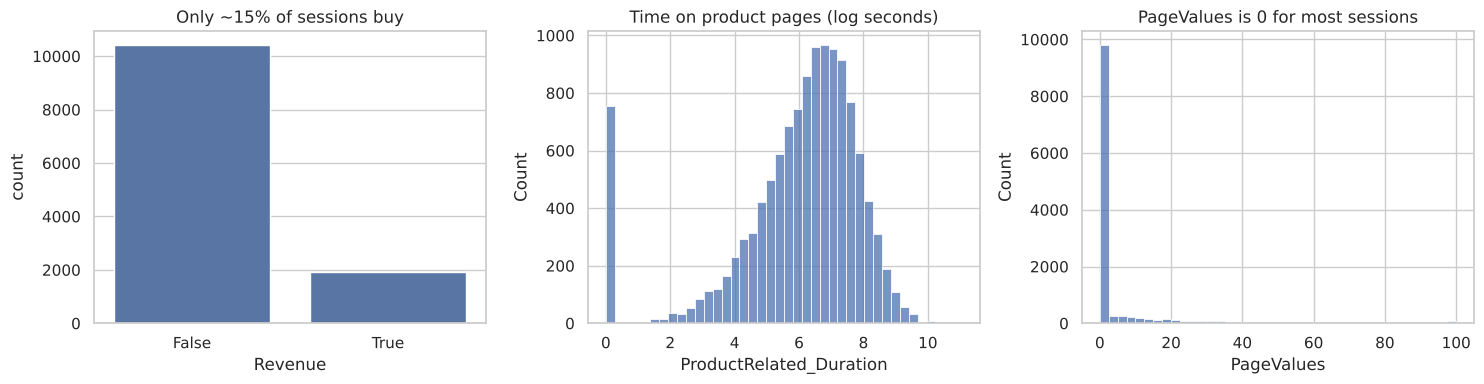

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="Revenue", data=df, ax=axes[0]).set(title="Only ~15% of sessions buy")
sns.histplot(np.log1p(df["ProductRelated_Duration"]), bins=40, ax=axes[1]).set(title="Time on product pages (log seconds)")
sns.histplot(df["PageValues"].clip(upper=100), bins=40, ax=axes[2]).set(title="PageValues is 0 for most sessions")
plt.tight_layout(); plt.show()

### Bivariate

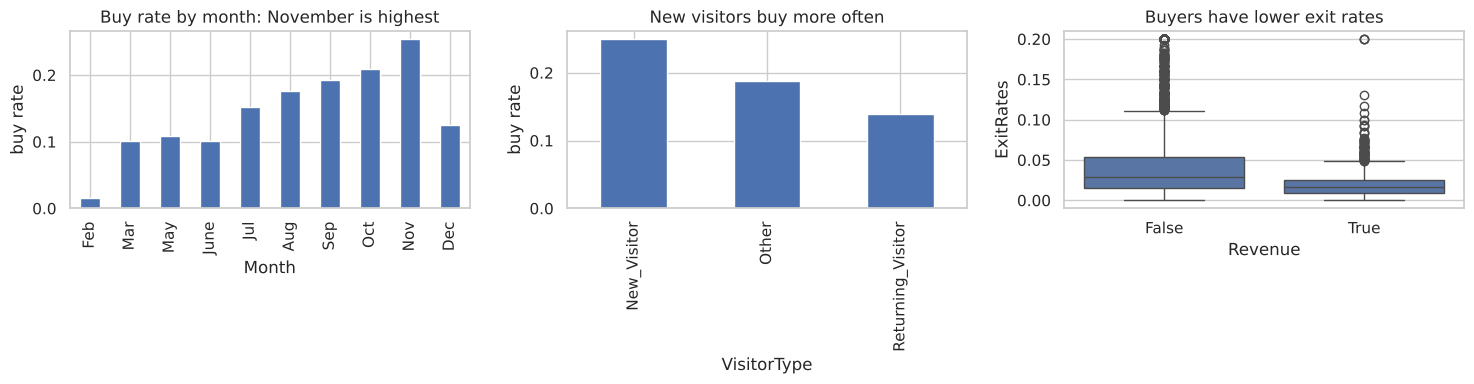

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = ["Feb","Mar","May","June","Jul","Aug","Sep","Oct","Nov","Dec"]
df.groupby("Month")["Revenue"].mean().reindex(order).plot(kind="bar", ax=axes[0], title="Buy rate by month: November is highest")
df.groupby("VisitorType")["Revenue"].mean().plot(kind="bar", ax=axes[1], title="New visitors buy more often")
sns.boxplot(x="Revenue", y="ExitRates", data=df, ax=axes[2]).set(title="Buyers have lower exit rates")
for ax in axes[:2]: ax.set_ylabel("buy rate")
plt.tight_layout(); plt.show()

In [6]:
pv = df.assign(has_page_value=df["PageValues"] > 0).groupby("has_page_value")["Revenue"].mean()
print("Buy rate when PageValues = 0:", round(pv[False], 3))
print("Buy rate when PageValues > 0:", round(pv[True], 3))

Buy rate when PageValues = 0: 0.039
Buy rate when PageValues > 0: 0.563


### Multivariate

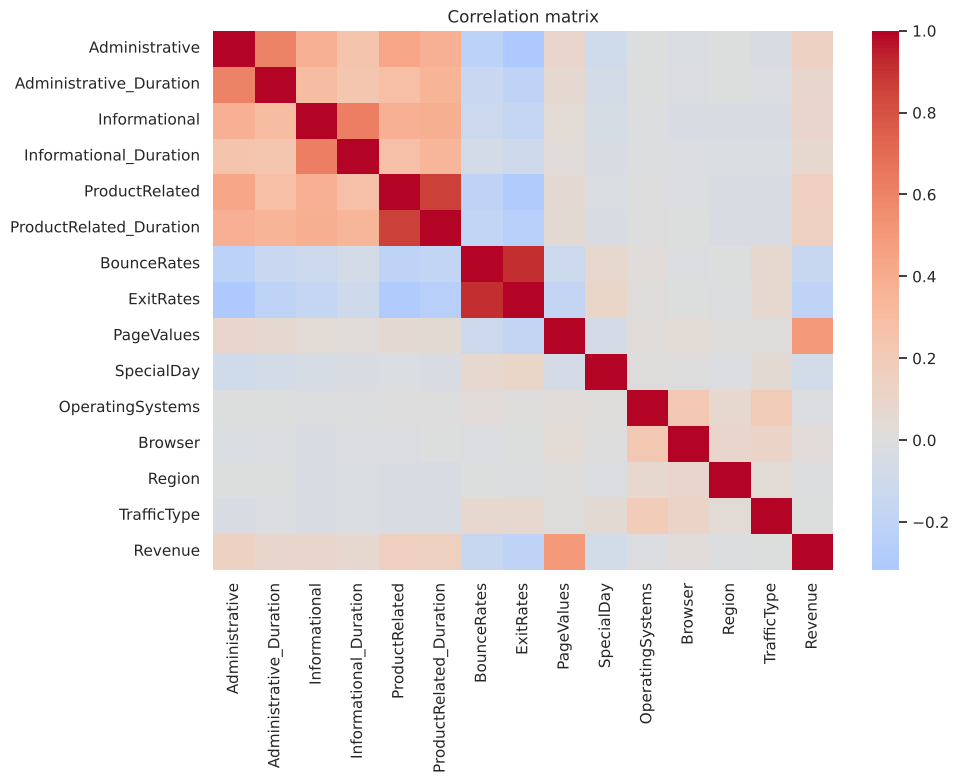

In [7]:
num = df.select_dtypes("number")
plt.figure(figsize=(10, 7))
sns.heatmap(num.assign(Revenue=df["Revenue"].astype(int)).corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix"); plt.show()

### Insights
1. **PageValues is the strongest signal.** Sessions with PageValues > 0 buy 56% of the time, compared with only 4% when it is 0.
2. **Exit and bounce rates are lower for buyers**, and the two are highly correlated with each other (r = 0.91), so they carry almost the same information.
3. **November has the highest buy rate** (25%, holiday season), while February has almost none (1.6%).
4. **New visitors convert more than returning visitors** (25% vs 14%), which suggests returning visitors often come back just to browse.
5. Page counts and their durations are strongly correlated (ProductRelated vs its duration: r = 0.86), so a time-per-page feature may add more than either one alone.

## 4 · Preprocessing
- Split **first** (stratified 80/20), then fit everything inside a `Pipeline`, so nothing from the test set leaks into training.
- **Outliers:** durations are very right-skewed, so we apply `log1p` instead of removing rows (big durations are real sessions).
- **Encoding:** one-hot for Month, VisitorType and the ID-like categoricals (OS, Browser, Region, TrafficType). `handle_unknown="ignore"` so the app never crashes on a new value.
- **Scaling:** StandardScaler for numeric features (needed by logistic regression).
- **Feature engineering:** total pages, total duration, average seconds per product page, and a flag for PageValues > 0.

In [8]:
from features import add_features   # kept in features.py so the app can load the pipeline

skewed = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration",
          "TotalDuration", "SecPerProductPage", "PageValues"]
numeric = ["Administrative", "Informational", "ProductRelated", "BounceRates", "ExitRates",
           "SpecialDay", "TotalPages", "HasPageValue", "Weekend"]
categorical = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]

preprocess = ColumnTransformer([
    ("skewed", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), skewed),
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])

def make_pipe(model):
    return Pipeline([("features", FunctionTransformer(add_features)), ("prep", preprocess), ("model", model)])

X = df.drop(columns="Revenue")
y = df["Revenue"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, "| buy rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

(9864, 17) (2466, 17) | buy rate train/test: 0.155 0.155


## 5 · Modeling: baseline + 4 algorithms
5-fold stratified cross-validation on the **training set only**. `class_weight="balanced"` makes the models care about the rare buyers.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
rows = []
for name, m in models.items():
    auc = cross_val_score(make_pipe(m), X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    f1 = cross_val_score(make_pipe(m), X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    rows.append({"model": name, "CV ROC-AUC": auc.mean(), "AUC std": auc.std(), "CV F1": f1.mean()})
cv_results = pd.DataFrame(rows).sort_values("CV ROC-AUC", ascending=False).round(3)
cv_results

,model,CV ROC-AUC,AUC std,CV F1
3,Random Forest,0.931,0.004,0.688
4,Gradient Boosting,0.931,0.004,0.680
1,Logistic Regression,0.921,0.004,0.657
2,Decision Tree,0.907,0.005,0.630
0,Baseline (majority class),0.500,0.000,0.000


The baseline gets F1 = 0 because it never predicts a buyer, which is exactly why accuracy alone would fool us.

## 6 · Hyperparameter tuning (grid search, training data only)

In [10]:
grids = {
    "Random Forest": (RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
                      {"model__n_estimators": [300], "model__max_depth": [8, 12, None], "model__min_samples_leaf": [1, 5, 10]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                          {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, 6, None], "model__max_iter": [200, 400]}),
}
tuned = {}
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipe(m), grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name}: best CV ROC-AUC = {gs.best_score_:.3f} | {gs.best_params_}")

best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_model = tuned[best_name].best_estimator_
print("\nSelected model:", best_name)

Random Forest: best CV ROC-AUC = 0.933 | {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}


Gradient Boosting: best CV ROC-AUC = 0.933 | {'model__learning_rate': 0.03, 'model__max_depth': None, 'model__max_iter': 200}

Selected model: Gradient Boosting


### Choosing the threshold
The default 0.5 is not always the best for the business. We pick the threshold that maximizes F1 **using cross-validated predictions on the training set**, so the test set stays untouched.

In [11]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_t = float(thr[np.argmax(f1s[:-1])])
print(f"Best threshold (max F1 on CV): {best_t:.2f}")

Best threshold (max F1 on CV): 0.68


## 7 · Final evaluation on the untouched test set

In [12]:
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= best_t).astype(int)
base_pred = np.zeros_like(y_test)

final = pd.DataFrame({
    "Baseline": [(base_pred == y_test).mean(), 0, 0, 0, 0.5],
    best_name: [(pred == y_test).mean(), precision_score(y_test, pred), recall_score(y_test, pred),
                f1_score(y_test, pred), roc_auc_score(y_test, proba)],
}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).round(3)
final

,Baseline,Gradient Boosting
Accuracy,0.845,0.895
Precision,0.000,0.646
Recall,0.000,0.707
F1,0.000,0.675
ROC-AUC,0.500,0.930


              precision    recall  f1-score   support

 No purchase       0.95      0.93      0.94      2084
    Purchase       0.65      0.71      0.68       382

    accuracy                           0.89      2466
   macro avg       0.80      0.82      0.81      2466
weighted avg       0.90      0.89      0.90      2466



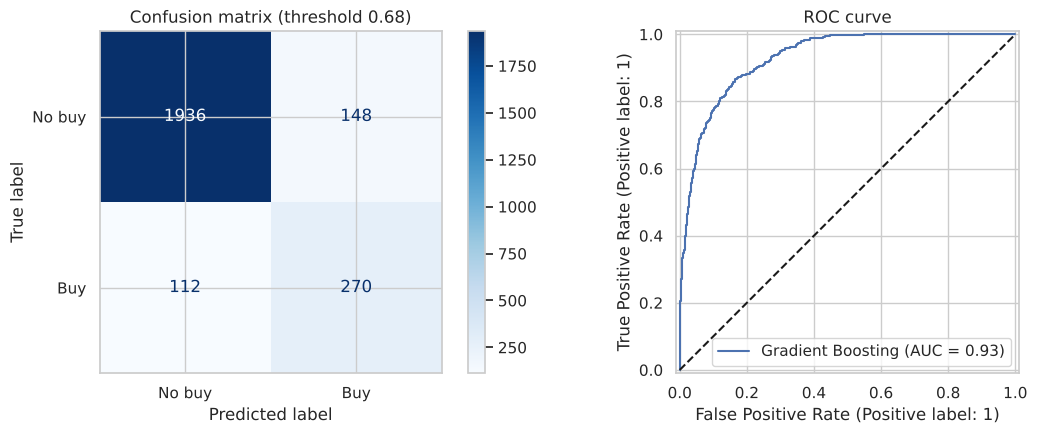

In [13]:
print(classification_report(y_test, pred, target_names=["No purchase", "Purchase"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No buy", "Buy"], cmap="Blues", ax=axes[0])
axes[0].set_title(f"Confusion matrix (threshold {best_t:.2f})")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

### Feature importance (permutation, on the test set)

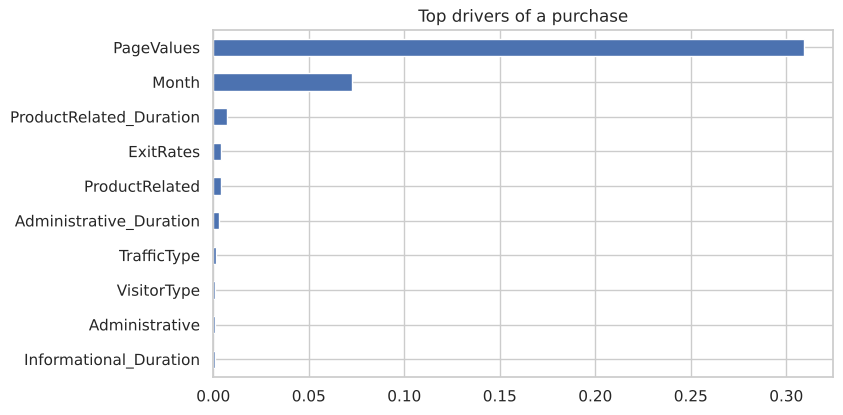

In [14]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=True).tail(10)
imp.plot(kind="barh", figsize=(8, 4.5), title="Top drivers of a purchase"); plt.show()

### Error analysis

In [15]:
test = X_test.assign(actual=y_test.values, proba=proba, pred=pred)
fn = test[(test.actual == 1) & (test.pred == 0)]
fp = test[(test.actual == 0) & (test.pred == 1)]
print(f"Missed buyers (FN): {len(fn)} | False alarms (FP): {len(fp)}")
print("\nShare of missed buyers with PageValues = 0:", round((fn.PageValues == 0).mean(), 2))
print("Share of all buyers with PageValues = 0:  ", round((test[test.actual == 1].PageValues == 0).mean(), 2))
test.groupby(["actual", "pred"])[["PageValues", "ExitRates", "ProductRelated"]].median().round(3)

Missed buyers (FN): 112 | False alarms (FP): 148

Share of missed buyers with PageValues = 0: 0.74
Share of all buyers with PageValues = 0:   0.22


PageValues  ExitRates  ProductRelated
actual pred                                       
0      0          0.000      0.029            15.0
       1         17.240      0.019            36.0
1      0          0.000      0.024            33.5
       1         23.039      0.014            28.0

Most missed buyers have **PageValues = 0**: they bought without passing through pages that usually lead to a purchase, so their session looks just like a browser's. False alarms are the opposite: visitors with high PageValues who still left, which are exactly the people a coupon could convert.

## 8 · Business insight
- The baseline looks good on accuracy (84.5%) but finds **zero** buyers. Our tuned Gradient Boosting model reaches **ROC-AUC 0.93** on the test set and catches **71% of buyers** with 65% precision.
- **Suggested use in the app:**
  - probability ≥ 0.68 → **no action**, they will probably buy anyway (don't waste a discount)
  - 0.30 – 0.68 → **show a coupon**, these are the undecided visitors where a nudge can matter
  - below 0.30 but browsed 20+ product pages → **open a chat**, interested but stuck
  - otherwise → no action, just browsing
- **PageValues** is by far the main driver, followed by session context like Month and ExitRates, so the team should track these live.
- **Limitations:** data is from one store and one year (no Jan / Apr), PageValues is only known after some browsing, so very early in a session the prediction is weaker, and the model shows correlation, not the effect of a coupon (an A/B test is needed for that).

## 9 · Save the final pipeline for the app

In [16]:
joblib.dump({"model": best_model, "threshold": best_t, "model_name": best_name}, "model.joblib")
print("Saved model.joblib")

Saved model.joblib
